# MVDR anti-jam beamforming: classical reference

This notebook is the classical baseline for the QSVT project. It models a uniform linear array
looking for a weak target at 0° while jammers transmit from other angles, computes MVDR weights
w = R⁻¹a / (a†R⁻¹a), and shows how jammer power controls the condition number κ of R.

**Conventions**
- Angles are in **degrees** everywhere in the public functions.
- Powers are per-element, relative to a noise power of 1 (so a power in dB is also a ratio to noise).
- `M = 8` elements, a power of two, so R fits on 3 qubits later.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

RNG = np.random.default_rng(seed=7)  # fixed seed for reproducibility

## Building blocks

In [ ]:
def steering_vector(theta_deg: float, m: int, d: float = 0.5) -> np.ndarray:
    """Array fingerprint for a plane wave arriving from theta_deg.

    Inputs: angle in degrees from broadside, number of elements m, spacing d in wavelengths.
    Output: complex vector of length m with entries exp(-2j*pi*d*n*sin(theta)).
    """
    theta = np.deg2rad(theta_deg)
    return np.exp(-2j * np.pi * d * np.arange(m) * np.sin(theta))


def db2lin(db: float | np.ndarray) -> float | np.ndarray:
    """Convert a power ratio in dB to linear units."""
    return 10 ** (np.asarray(db) / 10)


def exact_covariance(m: int, jammer_deg: list[float], jnr_db: list[float],
                     noise_power: float = 1.0) -> np.ndarray:
    """Ideal interference-plus-noise covariance R = sum_k J_k v_k v_k^H + sigma^2 I.

    This is the deterministic matrix the QSVT experiments will invert; kappa is known in closed form
    for one jammer: kappa = 1 + m * J / sigma^2.
    """
    r = noise_power * np.eye(m, dtype=complex)
    for ang, jnr in zip(jammer_deg, jnr_db):
        v = steering_vector(ang, m)
        r += noise_power * db2lin(jnr) * np.outer(v, v.conj())
    return r


def simulate_snapshots(m: int, source_deg: list[float], power_db: list[float], t: int,
                       rng: np.random.Generator, noise_power: float = 1.0) -> np.ndarray:
    """Simulate t snapshots (an m x t matrix) of independent complex Gaussian sources plus noise.

    Amplitudes are scaled by sqrt(power) so the per-element powers match power_db exactly.
    """
    def cn(shape):
        return (rng.standard_normal(shape) + 1j * rng.standard_normal(shape)) / np.sqrt(2)

    x = np.sqrt(noise_power) * cn((m, t))
    for ang, p in zip(source_deg, power_db):
        x += np.sqrt(noise_power * db2lin(p)) * np.outer(steering_vector(ang, m), cn(t))
    return x


def sample_covariance(x: np.ndarray) -> np.ndarray:
    """Sample covariance (1/t) X X^H of an m x t snapshot matrix."""
    return x @ x.conj().T / x.shape[1]


def mvdr_weights(r: np.ndarray, a: np.ndarray, loading: float = 0.0) -> np.ndarray:
    """MVDR weights w = (R + delta I)^-1 a / (a^H (R + delta I)^-1 a), normalized to w^H a = 1."""
    u = np.linalg.solve(r + loading * np.eye(len(a)), a)
    return u / (a.conj() @ u)


def beam_pattern_db(w: np.ndarray, angles_deg: np.ndarray) -> np.ndarray:
    """Array power response |w^H a(theta)|^2 in dB, normalized so the look direction is 0 dB."""
    m = len(w)
    resp = np.array([abs(w.conj() @ steering_vector(th, m)) ** 2 for th in angles_deg])
    return 10 * np.log10(resp / abs(w.conj() @ steering_vector(0.0, m)) ** 2 + 1e-15)


def condition_number(r: np.ndarray) -> float:
    """kappa = largest eigenvalue / smallest eigenvalue of a Hermitian positive definite matrix."""
    eig = np.linalg.eigvalsh(r)
    return eig[-1] / eig[0]

## Scenario

The target sits at 0°. One jammer at 22° is 40 dB above the noise. As is standard for MVDR,
R is estimated from *target-free* training snapshots (interference plus noise only). Including
the target in R causes "self-nulling" when the model is slightly off.

In [ ]:
M = 8
TARGET_DEG = 0.0
JAMMER_DEG = [22.0]  # near a sidelobe peak; 30 deg is a natural null for M = 8
JNR_DB = [40.0]
T = 2000  # training snapshots (Reed-Mallett-Brennan says ~2M is enough for near-optimal SINR)

a = steering_vector(TARGET_DEG, M)
R_exact = exact_covariance(M, JAMMER_DEG, JNR_DB)
R_hat = sample_covariance(simulate_snapshots(M, JAMMER_DEG, JNR_DB, T, RNG))

w_conv = a / M
w_mvdr = mvdr_weights(R_exact, a)
w_mvdr_hat = mvdr_weights(R_hat, a)

print(f"kappa(R_exact) = {condition_number(R_exact):,.0f}  (formula 1 + M*J = {1 + M*db2lin(40):,.0f})")
print(f"kappa(R_hat)   = {condition_number(R_hat):,.0f}")

X_train = simulate_snapshots(M, JAMMER_DEG, [20], 2**3, RNG)
X = np.hstack([X_train, np.sqrt(2**3 * 20) * np.eye(M)])

R_hat = sample_covariance(X)
w_mvdr_hat = mvdr_weights(R_hat, a)
# Make some loading columns, making inversion a bit easier

kappa(R_exact) = 80,001  (formula 1 + M*J = 80,001)
kappa(R_hat)   = 86,667


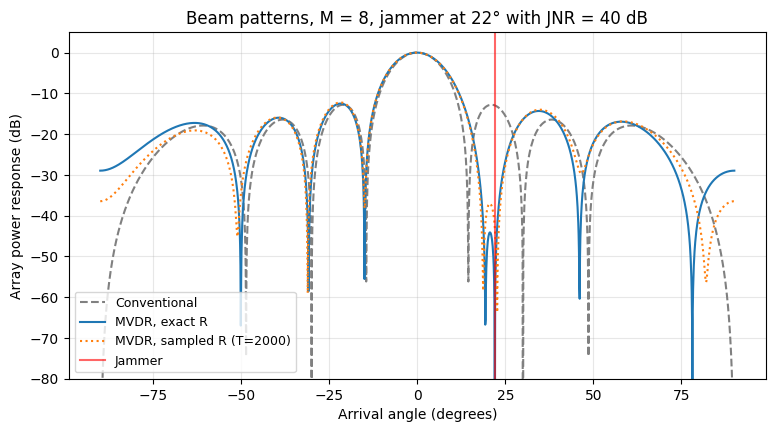

conventional  gain toward jammer:   -12.9 dB
MVDR exact    gain toward jammer:  -110.6 dB
MVDR sampled  gain toward jammer:   -42.7 dB


In [ ]:
angles = np.linspace(-90, 90, 1801)
plt.figure(figsize=(9, 4.5))
plt.plot(angles, beam_pattern_db(w_conv, angles), "--", color="gray", label="Conventional")
plt.plot(angles, beam_pattern_db(w_mvdr, angles), label="MVDR, exact R")
plt.plot(angles, beam_pattern_db(w_mvdr_hat, angles), ":", label=f"MVDR, sampled R (T={T})")
for j in JAMMER_DEG:
    plt.axvline(j, color="red", alpha=0.6, label="Jammer")
plt.ylim(-80, 5)
plt.xlabel("Arrival angle (degrees)")
plt.ylabel("Array power response (dB)")
plt.title("Beam patterns, M = 8, jammer at 22° with JNR = 40 dB")
plt.legend(loc="lower left", fontsize=9)
plt.grid(alpha=0.3)
plt.show()

for name, w in [("conventional", w_conv), ("MVDR exact", w_mvdr), ("MVDR sampled", w_mvdr_hat)]:
    print(f"{name:13s} gain toward jammer: {beam_pattern_db(w, np.array(JAMMER_DEG))[0]:7.1f} dB")

## Controlling the condition number

For one jammer the eigenvalues of R are σ² + M·J (one of them) and σ² (the other M − 1),
so **κ = 1 + M·JNR**. You raise κ by raising jammer power (or element count). Extra jammers add
more large eigenvalues but don't change the smallest one, so the strongest jammer sets κ.
Diagonal loading δ caps it: κ = (σ² + M·J + δ)/(σ² + δ).

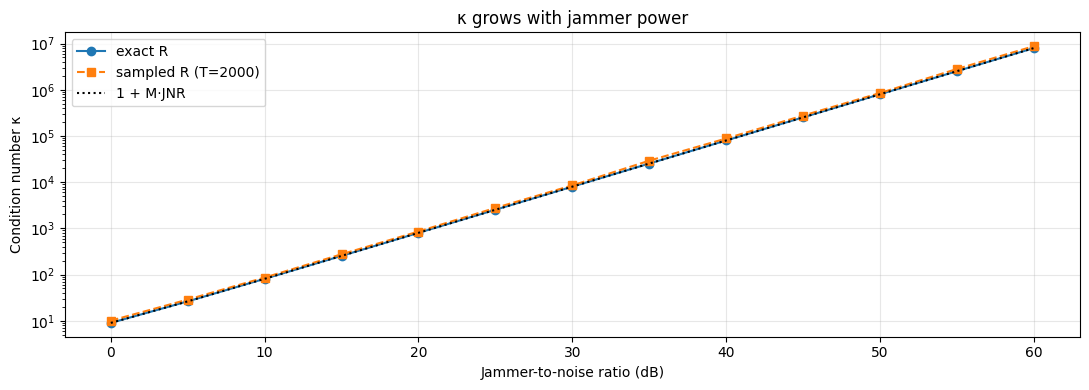

In [ ]:
jnr_sweep = np.arange(0, 61, 5)
kappa_exact = [condition_number(exact_covariance(M, JAMMER_DEG, [j])) for j in jnr_sweep]
kappa_hat = [condition_number(sample_covariance(simulate_snapshots(M, JAMMER_DEG, [j], T, RNG)))
             for j in jnr_sweep]
null_depth = [beam_pattern_db(mvdr_weights(exact_covariance(M, JAMMER_DEG, [j]), a),
                              np.array(JAMMER_DEG))[0] for j in jnr_sweep]

fig, ax = plt.subplots(1, 1, figsize=(11, 4))
ax.semilogy(jnr_sweep, kappa_exact, "o-", label="exact R")
ax.semilogy(jnr_sweep, kappa_hat, "s--", label=f"sampled R (T={T})")
ax.semilogy(jnr_sweep, 1 + M * db2lin(jnr_sweep), "k:", label="1 + M·JNR")
ax.set(xlabel="Jammer-to-noise ratio (dB)", ylabel="Condition number κ", title="κ grows with jammer power")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Aside: the Capon spectrum (direction finding)

Your tutorial code computed this. Scanning P(θ) = 1 / (a(θ)ᴴ R⁻¹ a(θ)) over angles shows *where*
energy arrives. It uses the same R⁻¹ but answers a different question than the beam pattern above,
which shows how one fixed set of weights *filters* each direction.

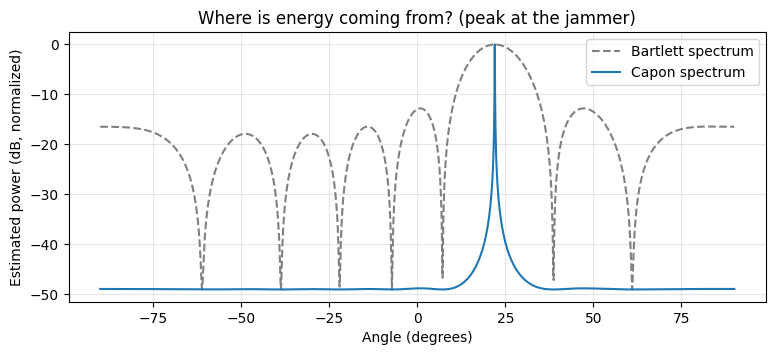

In [ ]:
R_inv = np.linalg.inv(R_exact)
capon = np.array([1 / np.real(steering_vector(th, M).conj() @ R_inv @ steering_vector(th, M)) for th in angles])
bartlett = np.array([np.real(steering_vector(th, M).conj() @ R_exact @ steering_vector(th, M)) / M**2 for th in angles])
plt.figure(figsize=(9, 3.5))
plt.plot(angles, 10 * np.log10(bartlett / bartlett.max()), "--", color="gray", label="Bartlett spectrum")
plt.plot(angles, 10 * np.log10(capon / capon.max()), label="Capon spectrum")
plt.xlabel("Angle (degrees)"); plt.ylabel("Estimated power (dB, normalized)")
plt.title("Where is energy coming from? (peak at the jammer)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

# Running MVDR on a Quantum Computer

In [ ]:
# Figure out how to put X in a state
# Elements to encode

n_elements = np.prod(np.shape(X))
print(n_elements)
print("Qubits needed ", np.ceil(np.log2(M))*np.log2(np.shape(X)[1]))

128
Qubits needed  12.0


In [ ]:
%pip install qiskit
%pip install pyqsp

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.5/9.5 MB 24.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 33.7 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [qiskit]
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for pyqsp: filename=pyqsp-0.2.0-py3-none-any.whl size=68414 sha256=8942925c83acdb67c538b59c5f53fbffd7ada795053efdf929f88bee4ecf523d
  Stored in directory: /root/.cache/pip/wheels/79/c4/4b/49b5263e9e436cc573a4542750be7bc720a1ac450fc24ea0ae
Successfully built pyqsp


In [ ]:
import qiskit as qis
from qiskit.circuit.library import StatePreparation

Set circuit

In [ ]:
sign = qis.QuantumRegister(1, "sign")
phase = qis.QuantumRegister(1, "phase")
time = qis.QuantumRegister(int(np.log2(np.shape(X)[1])), "time")
arrays = qis.QuantumRegister(int(np.log2(M)), "arrays")
qsvt = qis.QuantumRegister(int(np.log2(M)), "qsvt")
registers = [sign, phase, time, arrays, qsvt]
qc = qis.QuantumCircuit(*registers)


$|\psi_t\rangle$ is a $dxs$ state, where $d$ is the size of the vector and $s$ is the number of snapshots. In order to make the covariance matrix $R = \sum_t X^\dagger X$, these snapshots will be summed over, so we can put these snapshots in a state like $|\psi\rangle = |t\rangle |\psi(t)\rangle $, where each $d$ entries respresent one snapshot.  R will then be a partial density matrix of this state that we will talk about how to obtain later.

In [ ]:
# Vectorize X and get the unitary that preps the state
X_vec = np.reshape(X.T,-1)
psi = X_vec / np.linalg.norm(X_vec)
prep = StatePreparation(psi, label="prep")

In [ ]:
# psi: normalized complex vector, length 2**n
qc.append(prep, [*arrays, *time])
qc.append(prep.inverse(), [*arrays, *time]) # U-dagger, needed for the block encoding

We can block encode by encoding the density matrix of a prepped state since this is a correlation matrix.

$$
  W=\left(U^{\dagger} \otimes I_C\right)\left(\mathrm{SWAP}_{A, C} \otimes I_B\right)\left(U \otimes I_C\right)
$$



Block Encoding scheme, where U is the unitary that preps the state. THis formula for block encoding is from page 42: https://arxiv.org/pdf/1806.01838 . The proof is formula is verified below.

If we have a two regester state $|0\rangle^{\otimes a + s}$ that has an operator $U$ such that $U|0\rangle|0\rangle = \sum_{k=1}^r \sqrt{p_k} |\phi_k\rangle|\psi_k\rangle$

$$
\langle0|^{\otimes a+s} \langle \psi_i|(U^\dagger \otimes I_s)(I_a \otimes \text{SWAP}_s)(U \otimes I_C) |0\rangle^{\otimes a + s} |\psi_j \rangle
$$

$$
\sum_{k=1}^r \sqrt{\rho_k}\langle\phi_k|\langle \psi_k| \langle\psi_i|)(I_a \otimes \text{SWAP}_s) \sum^r_{l=1} \sqrt{\rho_l} |\phi_l\rangle |\psi_l\rangle |\psi_j\rangle
$$

$$
\sum_{k=1}^r \sum^r_{l=1} \sqrt{\rho_l} \sqrt{\rho_k}\langle\phi_k|\langle \psi_k| \langle\psi_i|   |\phi_l\rangle |\psi_j\rangle |\psi_l\rangle
$$

$$
\sum_{k=1}^r \sum^r_{l=1} \sqrt{\rho_l} \sqrt{\rho_k} \delta_{kl} \delta_{kj} \delta_{il}
$$

$$
\sqrt{\rho_i~\rho_j} \delta_{ij} = \langle\psi_i| \rho |\psi_j\rangle
$$

**Note**: this procedure already traces out the larger bit space of $\rho$, this is exactly what we need since out state is defined as $|\psi\rangle = |t\rangle |x(t)\rangle$ and we need the reduced density matrix $\rho = \sum_t |x(t)\rangle \langle x(t)|$

So, using this, we can prep the correct state $|\phi \rangle$ and apply the density matrix to it $\rho |\phi\rangle$

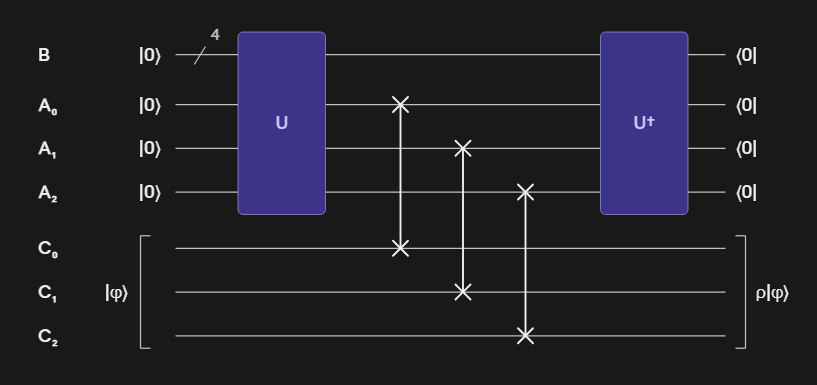


In [ ]:
# Implement the Above block encoding

qc.clear()

temp_qc = qis.QuantumCircuit(time, arrays, qsvt)

temp_qc.append(prep, [*arrays, *time])
for i in range(len(arrays)):
  temp_qc.swap(arrays[i], qsvt[i])
temp_qc.append(prep.inverse(), [*arrays, *time])

# Turn this circuit into a gate we can use for qsvt
U_f = temp_qc.to_gate(label="U_f")

We follow the standard procedure for implementing inversions via QSVT where one approximates $1/x$ with $(1 - \exp(-(kx)^2))/x$ where $k$ is an estimation of the matrix ocndition number. This formulation is advantageous because the taylor series converges quicker if the condition number is sufficiently small.

[PolyTaylorSeries] (Cheb) max 0.015626268293449753 is at 0.02237476632130652: normalizing
[PolyTaylorSeries] (Cheb) average error = 0.00018029258173618012 in the domain [-1, 1] using degree 200
[sym_qsp] Iterative optimization to err 1.000e-12 or max_iter 100.
iter: 001 --- err: 3.376e-02
iter: 002 --- err: 2.547e-04
iter: 003 --- err: 1.650e-08
iter: 004 --- err: 1.006e-15
[sym_qsp] Stop criteria satisfied.
[-7.68099757e-05  8.44673828e-05 -9.27245593e-05  1.01624352e-04
 -1.11212042e-04  1.21535423e-04 -1.32644886e-04  1.44593493e-04
 -1.57437056e-04  1.71234210e-04 -1.86046477e-04  2.01938334e-04
 -2.18977273e-04  2.37233851e-04 -2.56781741e-04  2.77697771e-04
 -3.00061958e-04  3.23957530e-04 -3.49470949e-04  3.76691909e-04
 -4.05713337e-04  4.36631378e-04 -4.69545366e-04  5.04557787e-04
 -5.41774223e-04  5.81303290e-04 -6.23256557e-04  6.67748444e-04
 -7.14896119e-04  7.64819363e-04 -8.17640427e-04  8.73483872e-04
 -9.32476382e-04  9.94746573e-04 -1.06042477e-03  1.12964277e-03
 -1

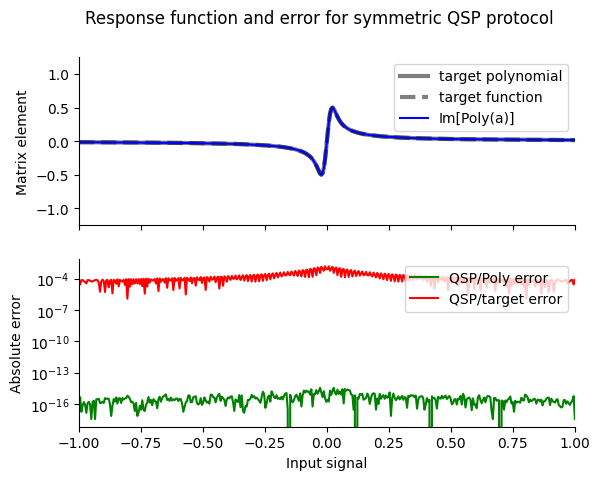

In [27]:
# takes a function and returns the chebeyschev polynomials
# copied this example from  https://github.com/ichuang/pyqsp#:~:text=Plot%20target%20and%20achieved%20functions%20to%20visualize%20result.

from pyqsp import angle_sequence, response
from pyqsp.poly import PolyTaylorSeries

# Specify definite-parity target function for QSP.
func = lambda x: (1-np.exp(-(10*5*x)**2))/x
polydeg = 200 # Desired QSP protocol length.
max_scale = 0.5 # Desired magnitude at the estimated extremum.

"""
Fit Chebyshev coefficients through degree 'polydeg' at 2*polydeg nodes.
This sampling rule does not rule out aliasing for an arbitrary callable.
"""
poly, scale = PolyTaylorSeries().taylor_series(
    func=func,
    degree=polydeg,
    max_scale=max_scale,
    return_scale=True,
    chebyshev_basis=True,
    cheb_samples=4*polydeg)
# max_scale is an estimated magnitude; scale is the multiplier actually used.
true_func = lambda x: scale * func(x)

# Compute full phases (and reduced phases, parity) using symmetric QSP.
(phiset, red_phiset, parity) = angle_sequence.QuantumSignalProcessingPhases(
    poly,
    method='sym_qsp',
    chebyshev_basis=True)

print(phiset)

response.PlotQSPResponse(
    phiset,
    pcoefs=poly,
    target=true_func,
    sym_qsp=True,
    simul_error_plot=True)

We use these angles to implement the cheyschev polynomials to apply a function $f$ to the singular values of our matrix $\rho$ and applying this inverted matrix to a state $|a_0\rangle$. The QSVT algorithm is shown below. Notice, there are just a few modifications.

Since, for us, $U = U^\dagger$, we do not need to alternate between $U$ and $U^\dagger$

Also, we have added a sign ancilla to get the magnitude of the polynonial we obtain from QSP. QSP returns a polynomial that has a real and imaginary part. We want the magnitude of this polynomial. The cnot gate makes it such that we apply $e^{i\phi} + e^{-i\phi}$, which results in getting the real part of the polynomial.

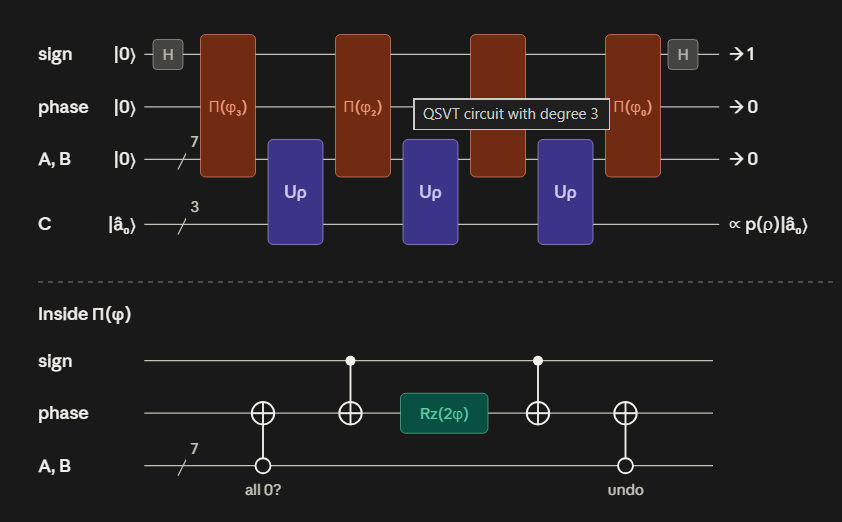

In [ ]:
import math
# Make code to create a circuit to do qsvt

# helper function

phiset[0] -= math.pi/4
phiset[-1] -= math.pi/4
phiset[1:-1] -= math.pi/2
def make_pi(phi, registers):
  sign, phase, time, arrays, qsvt = registers
  qc = qis.QuantumCircuit([*sign, *phase, *time, *arrays])
  qc.mcx([*time,*arrays], phase, ctrl_state="0"*7)
  qc.cx(sign,phase)
  qc.rz(2*phi, phase)
  qc.mcx([*time,*arrays], phase, ctrl_state="0"*7)
  qc.cx(sign,phase)
  qc.draw()
  Pi = qc.to_gate(label=f"Pi_{phi}")
  return Pi


# phi_set is the set of phis for the chebyschev polynomials
# U is the block encoding operator
# qc is the circuit
def run_qsvt(phi_set, U, registers):
  sign, phase, time, arrays, qsvt = registers

  qc = qis.QuantumCircuit([*sign, *phase, *time, *arrays, *qsvt])
  # initialize qsvt state to main signal being at theta = 0
  qc.h([*qsvt])
  qc.h(sign)
  for phi in phi_set[:-1]:
    pi = make_pi(phi, registers)
    qc.append(pi, [*sign, *phase, *time, *arrays])
    qc.append(U, [*time, *arrays, *qsvt])
  qc.append(make_pi(phi_set[-1], registers), [*sign, *phase, *time, *arrays])
  qc.h(sign)
  qc.draw()
  return qc
qc.clear()
make_pi(2, registers)
qsvt_circ = run_qsvt(phiset, U_f, registers)
qsvt_circ.draw()

┌───┐┌─────────────────────────┐        ┌─────────────────────────┐        »
 0: ┤ H ├┤0                        ├────────┤0                        ├────────»
    └───┘│                         │        │                         │        »
 1: ─────┤1                        ├────────┤1                        ├────────»
         │                         │┌──────┐│                         │┌──────┐»
 2: ─────┤2                        ├┤0     ├┤2                        ├┤0     ├»
         │                         ││      ││                         ││      │»
 3: ─────┤3                        ├┤1     ├┤3                        ├┤1     ├»
         │                         ││      ││                         ││      │»
 4: ─────┤4 Pi_-0.7854166615963286 ├┤2     ├┤4 Pi_-1.5707773767654158 ├┤2     ├»
         │                         ││      ││                         ││      │»
 5: ─────┤5                        ├┤3     ├┤5                        ├┤3     ├»
         │                         ││      ││                         ││      │»
 6: ─────┤6                        ├┤4     ├┤6                        ├┤4     ├»
         │                         ││  U_f ││                         ││  U_f │»
 7: ─────┤7                        ├┤5     ├┤7                        ├┤5     ├»
         │                         ││      ││                         ││      │»
 8: ─────┤8                        ├┤6     ├┤8                        ├┤6     ├»
    ┌───┐└─────────────────────────┘│      │└─────────────────────────┘│      │»
 9: ┤ H ├───────────────────────────┤7     ├───────────────────────────┤7     ├»
    ├───┤                           │      │                           │      │»
10: ┤ H ├───────────────────────────┤8     ├───────────────────────────┤8     ├»
    ├───┤                           │      │                           │      │»
11: ┤ H ├───────────────────────────┤9     ├───────────────────────────┤9     ├»
    └───┘                           └──────┘                           └──────┘»
«    ┌─────────────────────────┐        ┌─────────────────────────┐        »
« 0: ┤0                        ├────────┤0                        ├────────»
«    │                         │        │                         │        »
« 1: ┤1                        ├────────┤1                        ├────────»
«    │                         │┌──────┐│                         │┌──────┐»
« 2: ┤2                        ├┤0     ├┤2                        ├┤0     ├»
«    │                         ││      ││                         ││      │»
« 3: ┤3                        ├┤1     ├┤3                        ├┤1     ├»
«    │                         ││      ││                         ││      │»
« 4: ┤4 Pi_-1.5708157373155995 ├┤2     ├┤4 Pi_-1.5707764469685805 ├┤2     ├»
«    │                         ││      ││                         ││      │»
« 5: ┤5                        ├┤3     ├┤5                        ├┤3     ├»
«    │                         ││      ││                         ││      │»
« 6: ┤6                        ├┤4     ├┤6                        ├┤4     ├»
«    │                         ││  U_f ││                         ││  U_f │»
« 7: ┤7                        ├┤5     ├┤7                        ├┤5     ├»
«    │                         ││      ││                         ││      │»
« 8: ┤8                        ├┤6     ├┤8                        ├┤6     ├»
«    └─────────────────────────┘│      │└─────────────────────────┘│      │»
« 9: ───────────────────────────┤7     ├───────────────────────────┤7     ├»
«                               │      │                           │      │»
«10: ───────────────────────────┤8     ├───────────────────────────┤8     ├»
«                               │      │                           │      │»
«11: ───────────────────────────┤9     ├───────────────────────────┤9     ├»
«                               └──────┘                           └──────┘»
«    ┌─────────────────────────┐        ┌─────────────

# Run The Circuit!

Now we just run the circuit. However, the way in which we run the circuit shows a defect in the quantum approach to MVDR. We will have to use the Statevector function, which is a function only available when one one is simulating a quantum circuit on a classical computer using tensor networks. If we were to get a real quantum computer, we would need to chracterize the state fully using Quantum State Tomogrpahy, which takes about $3^n$ shots to characterize a state well.

This is because typical quantum measurement only gives you the probability of a state being measured via the born rule, which leaves out imaginary components of the state. Given that our vector is a vector of phases, the imaginary part is crucial.

If we wanted to avoid tomography and do an encoding for phases, we would have to adopt the strategy used by Quantum Phase Estimation (QPE), which encodes phases up to $\epsilon$ accuracy encoding them with $n$ bits, requires $t$ qubits where $t$ is calculated with.

$$
t=n+\left\lceil\log \left(2+\frac{1}{2 \epsilon}\right)\right\rceil
$$

This is all to say that if one wants to avoid doing tomography with a real quantum computer, we would have to find a way to encode the resulting phases of QSVT in a similar manner in which QPE does it. This means, this problem is not impossible, but getting sufficiently accurate readout would require more coherent, fault-tolerant qubits.

In [ ]:
from qiskit.quantum_info import Statevector

state = Statevector(qsvt_circ).data
n_anc = len(sign) + len(phase) + len(time) + len(arrays)
# only get states with all registers except qsvt register = 0. This is a basic requirement of QSVT
out = state[[c << n_anc for c in range(M)]]               # all ancillas 0 (incl. sign = 0), qsvt = c

p_success = np.linalg.norm(out) ** 2
w_qsvt = out / np.vdot(a, out)                            # MVDR normalization, w^H a = 1

w_ref = mvdr_weights(sample_covariance(X_train), a, loading=20)   # same data the circuit encodes
fidelity = abs(np.vdot(w_ref / np.linalg.norm(w_ref), w_qsvt / np.linalg.norm(w_qsvt))) ** 2

print("p_success:", p_success)
print("fidelity :", fidelity)
print("null at jammer (QSVT, classical):",
      beam_pattern_db(w_qsvt, np.array(JAMMER_DEG))[0],
      beam_pattern_db(w_ref, np.array(JAMMER_DEG))[0])

p_success: 0.03584068296311035
fidelity : 0.999999698775774
null at jammer (QSVT, classical): -42.75693766812793 -42.720141372509445


In [ ]:
def compare_methods(M, JAMMER_DEG, JNR_DB, T, registers, TARGET_DEG=0, approx_cond = 10):

  sign, phase, time, arrays, qsvt = registers

  polydeg = approx_cond*20

  a = steering_vector(TARGET_DEG, M)

  X_train = simulate_snapshots(M, JAMMER_DEG, JNR_DB, T, RNG)
  X = np.hstack([X_train, np.sqrt(T * 20) * np.eye(M)])

  R_hat = sample_covariance(X)
  U,S,V = np.linalg.svd(R_hat)
  w_mvdr_hat = mvdr_weights(R_hat, a)

  print("Smallest and largest SV ", np.min(S), np.max(S))

  # Specify definite-parity target function for QSP.
  func = lambda x: (1-np.exp(-(approx_cond*5*x)**2))/x
  max_scale = 0.7 # Desired magnitude at the estimated extremum.

  poly, scale = PolyTaylorSeries().taylor_series(
      func=func,
      degree=polydeg,
      max_scale=max_scale,
      return_scale=True,
      chebyshev_basis=True,
      cheb_samples=4*polydeg)
  print(scale)
  # max_scale is an estimated magnitude; scale is the multiplier actually used.
  true_func = lambda x: scale * func(x)

  # Compute full phases (and reduced phases, parity) using symmetric QSP.
  (phiset, red_phiset, parity) = angle_sequence.QuantumSignalProcessingPhases(
      poly,
      method='sym_qsp',
      chebyshev_basis=True)

  phiset[0] -= math.pi/4
  phiset[-1] -= math.pi/4
  phiset[1:-1] -= math.pi/2


  X_vec = np.reshape(X.T,-1)
  psi = X_vec / np.linalg.norm(X_vec)
  prep = StatePreparation(psi, label="prep")

  temp_qc = qis.QuantumCircuit(time, arrays, qsvt)

  temp_qc.append(prep, [*arrays, *time])
  for i in range(len(arrays)):
    temp_qc.swap(arrays[i], qsvt[i])
  temp_qc.append(prep.inverse(), [*arrays, *time])

  # Turn this circuit into a gate we can use for qsvt

  U_f = temp_qc.to_gate(label="U_f")

  temp_qc.draw()

  qsvt_circ = run_qsvt(phiset, U_f, registers)

  state = Statevector(qsvt_circ).data
  n_anc = len(sign) + len(phase) + len(time) + len(arrays)   # 9
  out = state[[c << n_anc for c in range(M)]]               # all ancillas 0 (incl. sign = 0), qsvt = c

  p_success = np.linalg.norm(out) ** 2
  w_qsvt = out / np.vdot(a, out)                            # MVDR normalization, w^H a = 1

  w_ref = mvdr_weights(sample_covariance(X_train), a, loading=20)   # same data the circuit encodes
  fidelity = abs(np.vdot(w_ref / np.linalg.norm(w_ref), w_qsvt / np.linalg.norm(w_qsvt))) ** 2

  print("p_success:", p_success)
  print("fidelity :", fidelity)
  print("Matrix condition number ", np.linalg.cond(R_hat))
  print("null at jammer (QSVT, classical):",
        beam_pattern_db(w_qsvt, np.array(JAMMER_DEG))[0],
        beam_pattern_db(w_ref, np.array(JAMMER_DEG))[0])

  return [fidelity, np.linalg.cond(R_hat)]


In [ ]:
results = []

polydeg = 120

for pow in [10,20,40,80,100,200]:

  results.append(compare_methods(8, [22], [pow], 2**3, registers,TARGET_DEG=0))

print(results)


Smallest and largest SV  10.008322081820626 56.322471672090295
[PolyTaylorSeries] (Cheb) max 0.021876775610829652 is at 0.02237476632130652: normalizing
[PolyTaylorSeries] (Cheb) average error = 0.0002524096144306522 in the domain [-1, 1] using degree 200
0.021876775610829652
[sym_qsp] Iterative optimization to err 1.000e-12 or max_iter 100.
iter: 001 --- err: 9.055e-02
iter: 002 --- err: 3.210e-03
iter: 003 --- err: 5.335e-06
iter: 004 --- err: 1.528e-11
iter: 005 --- err: 1.332e-15
[sym_qsp] Stop criteria satisfied.
p_success: 0.07001327204044736
fidelity : 0.999999690616785
Matrix condition number  5.62756386251756
null at jammer (QSVT, classical): -27.806720891777328 -27.808011766155097
Smallest and largest SV  10.006319753259763 312.86217123491144
[PolyTaylorSeries] (Cheb) max 0.021876775610829652 is at 0.02237476632130652: normalizing
[PolyTaylorSeries] (Cheb) average error = 0.0002524096144306522 in the domain [-1, 1] using degree 200
0.021876775610829652
[sym_qsp] Iterative opt

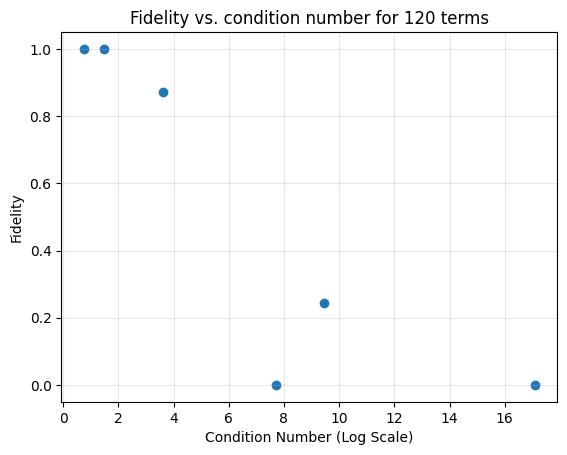

In [ ]:

def plot_results(results, polydeg):

  results = np.array(results)
  plt.scatter(np.log10(results[:,1]),results[:,0])
  plt.title(f"Fidelity vs. condition number for {polydeg} terms")
  plt.xlabel("Condition Number (Log Scale)")
  plt.ylabel("Fidelity")
  plt.grid(alpha=0.3)
  plt.show()

plot_results(results, polydeg)


In [ ]:
results = []

for pow in [10,20,40,80,100,200]:

  results.append(compare_methods(8, [22], [pow], 2**3, registers,TARGET_DEG=0, approx_cond=10))

print(results)

Smallest and largest SV  10.001211593008874 55.16549537940272
[PolyTaylorSeries] (Cheb) max 0.021876775610829652 is at 0.02237476632130652: normalizing
[PolyTaylorSeries] (Cheb) average error = 0.0002524096144306522 in the domain [-1, 1] using degree 200
0.021876775610829652
[sym_qsp] Iterative optimization to err 1.000e-12 or max_iter 100.
iter: 001 --- err: 9.055e-02
iter: 002 --- err: 3.210e-03
iter: 003 --- err: 5.335e-06
iter: 004 --- err: 1.528e-11
iter: 005 --- err: 1.332e-15
[sym_qsp] Stop criteria satisfied.
p_success: 0.07044736291287927
fidelity : 0.999999726910098
Matrix condition number  5.5158812376257496
null at jammer (QSVT, classical): -32.684288668396476 -32.562356539063636
Smallest and largest SV  10.003121862603404 380.68718142209894
[PolyTaylorSeries] (Cheb) max 0.021876775610829652 is at 0.02237476632130652: normalizing
[PolyTaylorSeries] (Cheb) average error = 0.0002524096144306522 in the domain [-1, 1] using degree 200
0.021876775610829652
[sym_qsp] Iterative op

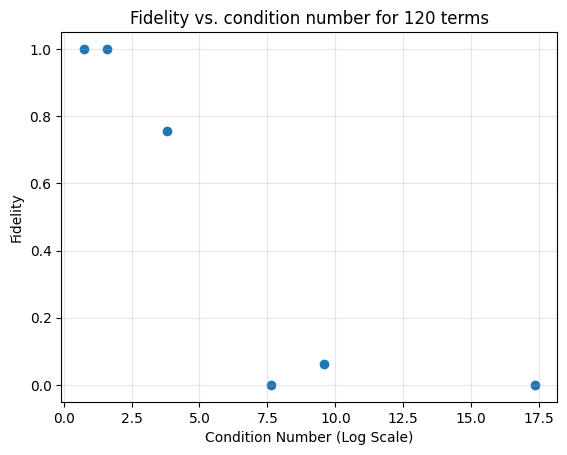

In [ ]:
plot_results(results, polydeg)

In [ ]:
results = []

for pow in [10,20,40,80,100,200]:

  results.append(compare_methods(8, [22], [pow], 2**3, registers,TARGET_DEG=0, approx_cond=50))

print(results)

Smallest and largest SV  10.003036843533607 48.08657845156864
[PolyTaylorSeries] (Cheb) max 0.004375371877364088 is at 0.004475008917331073: normalizing
[PolyTaylorSeries] (Cheb) average error = 7.46330560330807e-05 in the domain [-1, 1] using degree 1000
0.004375371877364088
[sym_qsp] Iterative optimization to err 1.000e-12 or max_iter 100.
iter: 001 --- err: 9.051e-02
iter: 002 --- err: 3.208e-03
iter: 003 --- err: 5.329e-06
iter: 004 --- err: 1.524e-11
iter: 005 --- err: 2.007e-15
[sym_qsp] Stop criteria satisfied.
p_success: 0.0024639933617248266
fidelity : 0.9999923899903941
Matrix condition number  4.807197974348545
null at jammer (QSVT, classical): -25.627999984102388 -25.612457040963687
Smallest and largest SV  10.006385862048482 333.30009798383696
[PolyTaylorSeries] (Cheb) max 0.004375371877364088 is at 0.004475008917331073: normalizing
[PolyTaylorSeries] (Cheb) average error = 7.46330560330807e-05 in the domain [-1, 1] using degree 1000
0.004375371877364088
[sym_qsp] Iterativ

Try to make polydeg = 20*k_est